In [1]:
import sys
import torch
import random
import torch.nn.functional as F
import matplotlib.pyplot as plt

from pathlib import Path
from torchvision import transforms
from collections import defaultdict

In [2]:
codebase_dir = Path.cwd().parent / "AVQ"
sys.path.insert(0, str(codebase_dir))

In [3]:
from avq.config import EXPERIMENT_REGISTRY

from avq.dataset import TinyImageNetValidationDataset, COCOImageDataset, MiniPlacesDataset
from avq.dataset import build_tiny_imagenet_loaders, build_mini_places_loaders, build_coco_loaders

# Tiny ImageNet

In [4]:
TINY_IMAGENET_ROOT = "/tmp/data/tiny-imagenet-200"
_, _, val_loader, class_to_idx, idx_to_label = build_tiny_imagenet_loaders(
    root_directory=TINY_IMAGENET_ROOT,
    batch_size=64,
    num_workers=4,
    image_size=64,
    seed=15,
    drop_last_train=True,
)

Tiny ImageNet data loaded
Root: /tmp/data/tiny-imagenet-200
Number of classes: 200
Training images: 95,000
Training-evaluation images: 5,000
Validation images: 10,000
Training batches: 1,484
Validation batches: 157


In [5]:
normalize = transforms.Normalize(mean=(0.5, 0.5, 0.5), std=(0.5, 0.5, 0.5))
evaluation_transform = transforms.Compose(
        [
            transforms.Resize(
                (64, 64),
                interpolation=transforms.InterpolationMode.BICUBIC,
            ),
            transforms.ToTensor(),
            normalize,
        ]
    )

val_dataset = TinyImageNetValidationDataset(
        val_directory="/tmp/data/tiny-imagenet-200/val",
        class_to_idx=class_to_idx,
        transform=evaluation_transform,
    )

In [6]:
def denormalize_image(image):
    """Convert image from [-1, 1] to [0, 1]."""
    return ((image + 1.0) / 2.0).clamp(0, 1)

@torch.inference_mode()
def reconstruct_image(method, model, image, device, temperature=0.02):
    """
    Reconstruct one image using hard discrete latents.

    image:
        [C, H, W]

    returns:
        [C, H, W] on CPU
    """
    image = image.unsqueeze(0).to(device)  # [1, C, H, W]

    if method == "avq":
        encoded = model.encoder(image)
        quantizer_outputs = model.quantizer(
            encoded,
            temperature=temperature,
        )

        hard_quantized = quantizer_outputs["hard_quantized"]
        reconstruction = model.decoder(hard_quantized)
    elif method == "arvq":
        outputs = model(
            image,
            temperature=temperature,
            mode="hard",
        )
        reconstruction = outputs["reconstruction"]
    else:
        outputs = model(image)
        reconstruction = outputs["reconstruction"]
        
    return reconstruction.squeeze(0).cpu()


def load_model(experiment_name, checkpoint, device):
    experiment = EXPERIMENT_REGISTRY[experiment_name]
    model = experiment.model_cls(**experiment.model_kwargs).to(device)
    state_dict = torch.load(
        checkpoint,
        map_location=device,
        weights_only=True,
    )

    model.load_state_dict(state_dict["model_state_dict"])
    model.eval()

    return model


def get_checkpoint_path(experiment_name, experiment_dir):
    method = experiment_name.split("_")[0]
    checkpoint_dir = experiment_dir / experiment_name / "calibration"

    if method == "arvq":
        pt_file = "best_arvq_decoder_calibration.pt"
    else:
        pt_file = "best_decoder_calibration.pt"

    return checkpoint_dir / pt_file


def plot_reconstruction_grid(
    experiment_order,
    row_names,
    visual_indices,
    experiment_dir,
    val_dataset,
    idx_to_label,
    figsize=None,
    save_path=None,
):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    nrows = len(experiment_order)
    ncols = len(visual_indices)

    if figsize is None:
        figsize = (12, 1.8 * nrows)

    fig, axes = plt.subplots(nrows, ncols, figsize=figsize, squeeze=False)
    visual_items = list(visual_indices.items())

    # Column titles
    for col, (_, idx) in enumerate(visual_items):
        _, actual_label = val_dataset[idx]

        class_name = display_names[actual_label]

        axes[0, col].set_title(
            class_name,
            fontsize=8,
            fontweight="bold",
        )

    # Rows
    for row, experiment_name in enumerate(experiment_order):

        if experiment_name == "original":

            for col, (_, idx) in enumerate(visual_items):
                image, _ = val_dataset[idx]

                display_image = denormalize_image(image)
                display_image = (
                    display_image
                    .permute(1, 2, 0)
                    .cpu()
                    .numpy()
                )

                axes[row, col].imshow(display_image)

        else:
            method = experiment_name.split("_")[0]

            checkpoint = get_checkpoint_path(
                experiment_name,
                experiment_dir,
            )

            print(
                f"Loading {experiment_name}: "
                f"{checkpoint}"
            )

            model = load_model(
                experiment_name,
                checkpoint,
                device,
            )

            for col, (_, idx) in enumerate(visual_items):
                image, _ = val_dataset[idx]

                reconstruction = reconstruct_image(
                    method,
                    model,
                    image,
                    device,
                    temperature=0.02,
                )

                display_image = denormalize_image(reconstruction)
                display_image = display_image.permute(1, 2, 0).numpy()
                axes[row, col].imshow(display_image)

            del model

            if device.type == "cuda":
                torch.cuda.empty_cache()

        # Hide ticks/spines but DO NOT call axis("off")
        for col in range(ncols):
            ax = axes[row, col]

            ax.set_xticks([])
            ax.set_yticks([])

            for spine in ax.spines.values():
                spine.set_visible(False)

        # # Method name on left
        axes[row, 0].set_ylabel(
            row_names[row],
            fontsize=10,
            fontweight="bold",
            rotation=0,
            labelpad=35,
            va="center",
        )

        # axes[row, 0].set_ylabel(
        #     row_names[row],
        #     fontsize=9,
        #     fontweight="bold",
        #     rotation=0,
        #     labelpad=25,
        #     va="center",
        # )

    plt.subplots_adjust(
        left=0.095,
        right=0.995,
        top=0.955,
        bottom=0.015,
        wspace=0.035,
        hspace=0.08,
    )

    if save_path is not None:
        plt.savefig(
            save_path,
            dpi=300,
            bbox_inches="tight",
            pad_inches=0.02,
        )

    plt.show()

Loading vq_16x16_k1024_d64: /tmp/data/experiments/qualitative/tiny-imagenet/seed-42/vq_16x16_k1024_d64/calibration/best_decoder_calibration.pt
Loading vqema_16x16_k1024_d64: /tmp/data/experiments/qualitative/tiny-imagenet/seed-42/vqema_16x16_k1024_d64/calibration/best_decoder_calibration.pt
Loading fsq_16x16_k1000_d64: /tmp/data/experiments/qualitative/tiny-imagenet/seed-42/fsq_16x16_k1000_d64/calibration/best_decoder_calibration.pt
Loading avq_16x16_k1024_d64: /tmp/data/experiments/qualitative/tiny-imagenet/seed-42/avq_16x16_k1024_d64/calibration/best_decoder_calibration.pt
Loading rvqema_16x16_q3_k1024_d64: /tmp/data/experiments/qualitative/tiny-imagenet/seed-42/rvqema_16x16_q3_k1024_d64/calibration/best_decoder_calibration.pt
Loading arvq_16x16_q3_k1024_d64: /tmp/data/experiments/qualitative/tiny-imagenet/seed-42/arvq_16x16_q3_k1024_d64/calibration/best_arvq_decoder_calibration.pt


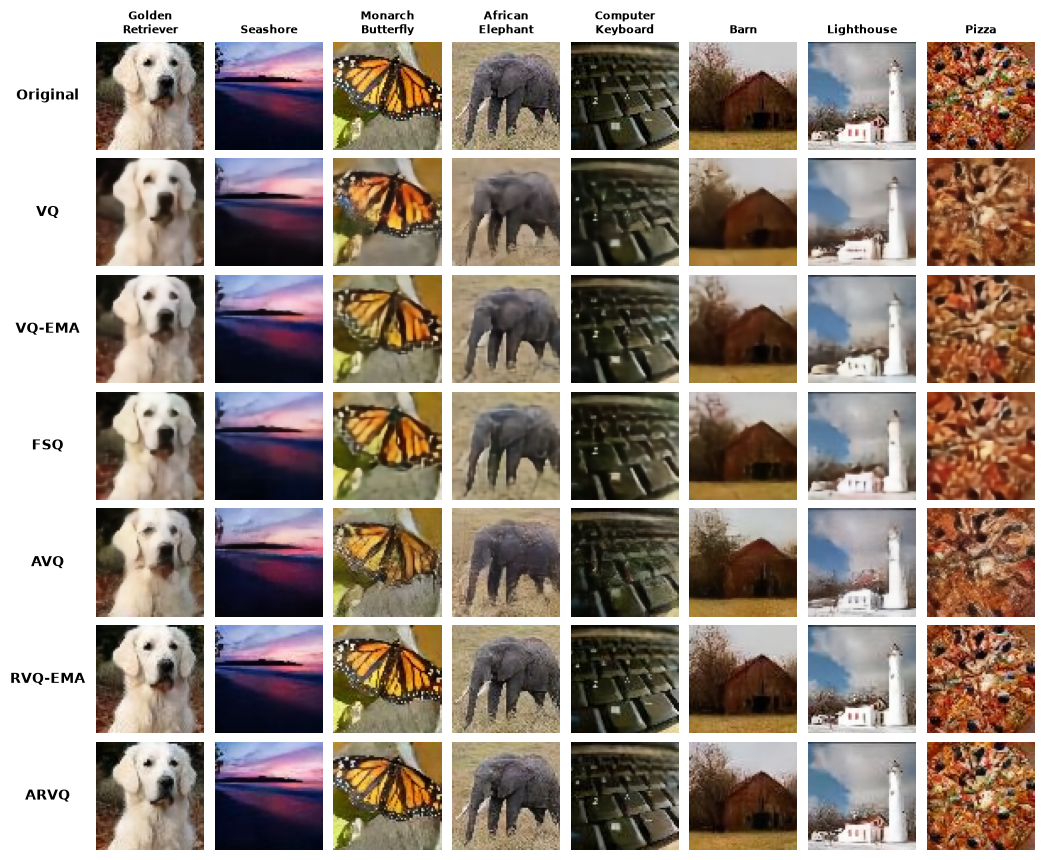

In [7]:
visual_indices = {
    26: 242,     # golden retriever
    198: 1457,   # seashore
    44: 9379,    # monarch butterfly
    57: 855,     # African elephant
    92: 825,     # computer keyboard
    66: 6675,    # barn
    71: 4977,    # lighthouse
    191: 2862,   # pizza
}

experiment_dir = Path("/tmp/data/experiments/qualitative/tiny-imagenet/seed-42/")

display_names = {
    26: "Golden\nRetriever",
    198: "Seashore",
    44: "Monarch\nButterfly",
    57: "African\nElephant",
    92: "Computer\nKeyboard",
    66: "Barn",
    71: "Lighthouse",
    191: "Pizza",
}

baseline_order = [
    "original",
    "vq_16x16_k1024_d64",
    "vqema_16x16_k1024_d64",
    "fsq_16x16_k1000_d64",
    "avq_16x16_k1024_d64",
    "rvqema_16x16_q3_k1024_d64",
    "arvq_16x16_q3_k1024_d64",
]

baseline_row_names = [
    "Original",
    "VQ",
    "VQ-EMA",
    "FSQ",
    "AVQ",
    "RVQ-EMA",
    "ARVQ",
]

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

plot_reconstruction_grid(
    experiment_order=baseline_order,
    row_names=baseline_row_names,
    visual_indices=visual_indices,
    experiment_dir=experiment_dir,
    val_dataset=val_dataset,
    idx_to_label=idx_to_label,
    figsize=(10.5, 8.6),
    save_path="imagenet_reconstructions.pdf",
)

# COCO

In [87]:
COCO_ROOT = "/tmp/data/coco2017"
_, _, val_loader, class_to_idx, idx_to_label = build_coco_loaders(
    root_directory=COCO_ROOT,
    batch_size=64,
    num_workers=4,
    image_size=64,
    seed=15,
    drop_last_train=True,
)

loading annotations into memory...
Done (t=11.88s)
creating index...
index created!
loading annotations into memory...
Done (t=11.85s)
creating index...
index created!
loading annotations into memory...
Done (t=0.49s)
creating index...
index created!
COCO data loaded
Root: /tmp/data/coco2017
Number of classes: 80
Training images: 113,287
Training-evaluation images: 5,000
Validation images: 5,000
Training batches: 1,770
Validation batches: 79


In [88]:
val_dataset = val_loader.dataset

print("Validation images:", len(val_dataset))
print("Number of COCO categories:", len(val_dataset.class_to_idx))

# Inspect available COCO categories
for category_name, category_id in sorted(val_dataset.class_to_idx.items(), key=lambda x: x[1]):
    print(f"{category_id:2d}: {category_name:20s} -> {len(val_dataset.category_to_indices[category_id]):4d} images")

Validation images: 5000
Number of COCO categories: 80
 1: person               -> 2693 images
 2: bicycle              ->  149 images
 3: car                  ->  535 images
 4: motorcycle           ->  159 images
 5: airplane             ->   97 images
 6: bus                  ->  189 images
 7: train                ->  157 images
 8: truck                ->  250 images
 9: boat                 ->  121 images
10: traffic light        ->  191 images
11: fire hydrant         ->   86 images
13: stop sign            ->   69 images
14: parking meter        ->   37 images
15: bench                ->  235 images
16: bird                 ->  125 images
17: cat                  ->  184 images
18: dog                  ->  177 images
19: horse                ->  128 images
20: sheep                ->   65 images
21: cow                  ->   87 images
22: elephant             ->   89 images
23: bear                 ->   49 images
24: zebra                ->   85 images
25: giraffe              -

Selected qualitative images:
bed       : dataset index = 1901, file = 000000218439.jpg
giraffe   : dataset index = 4866, file = 000000566042.jpg
bird      : dataset index = 4791, file = 000000558421.jpg
bench     : dataset index = 841, file = 000000098716.jpg
skis      : dataset index = 469, file = 000000052591.jpg


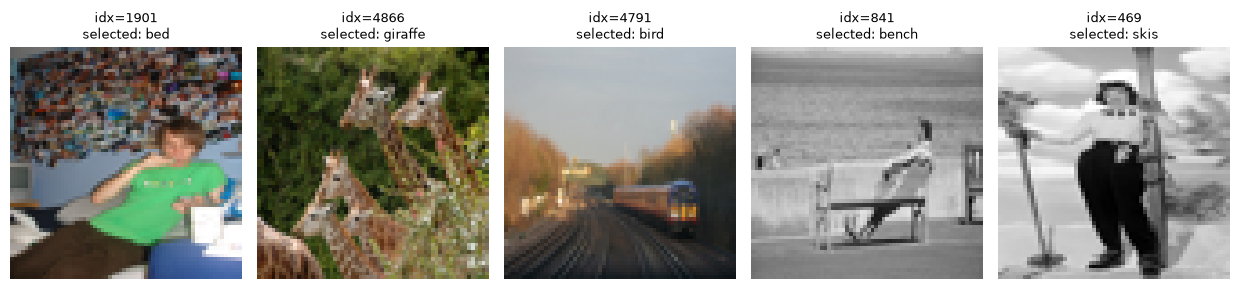

In [89]:
VIS_SEED = 44

rng = random.Random(VIS_SEED)

selected_category_names = [
    "bed",
    "giraffe",
    "bird",
    "bench",
    # "airplane",
    #"pizza",
    #"chair",
    #"clock",
    # "fire hydrant",
    # "wine glass",
    # "potted plant",
     "skis",
]

MIN_BOX_AREA_RATIO = 0.15

visual_indices = {}
used_indices = set()

for category_name in selected_category_names:
    category_id = val_dataset.class_to_idx[category_name]

    eligible_indices = []

    for idx in val_dataset.category_to_indices[category_id]:
        if idx in used_indices:
            continue

        # Recover the original COCO image id.
        image_path = val_dataset.samples[idx]
        file_name = image_path.name

        # Find corresponding image metadata.
        image_ids = val_dataset.coco.getImgIds(
            catIds=[category_id]
        )

        # Get this dataset item's COCO image id from filename.
        # COCO filenames are e.g. 000000123456.jpg.
        coco_image_id = int(image_path.stem)

        image_info = val_dataset.coco.loadImgs(
            coco_image_id
        )[0]

        image_area = (
            image_info["width"]
            * image_info["height"]
        )

        annotation_ids = val_dataset.coco.getAnnIds(
            imgIds=[coco_image_id],
            catIds=[category_id],
            iscrowd=None,
        )

        annotations = val_dataset.coco.loadAnns(
            annotation_ids
        )

        if not annotations:
            continue

        largest_box_area = max(
            ann["bbox"][2] * ann["bbox"][3]
            for ann in annotations
        )

        area_ratio = largest_box_area / image_area

        if area_ratio >= MIN_BOX_AREA_RATIO:
            eligible_indices.append(idx)

    if not eligible_indices:
        raise RuntimeError(
            f"No eligible images for {category_name}"
        )

    selected_idx = rng.choice(
        eligible_indices
    )

    visual_indices[category_name] = selected_idx
    used_indices.add(selected_idx)


print("Selected qualitative images:")

for category_name, idx in visual_indices.items():
    print(
        f"{category_name:10s}: "
        f"dataset index = {idx}, "
        f"file = {val_dataset.samples[idx].name}"
    )

def denormalize_image(x):
    # [-1, 1] -> [0, 1]
    return ((x + 1.0) / 2.0).clamp(0, 1)

num_images = len(visual_indices)

fig, axes = plt.subplots(1, num_images, figsize=(2.5 * num_images, 2.8))

if num_images == 1:
    axes = [axes]

for ax, (selected_category, idx) in zip(axes, visual_indices.items()):
    image, _ = val_dataset[idx]
    image = denormalize_image(image)
    image = image.permute(1, 2, 0).cpu().numpy()

    # All annotated categories in this COCO image.
    category_names = [val_dataset.idx_to_label[cid] for cid in val_dataset.category_ids[idx]]

    ax.imshow(image)
    ax.set_title(f"idx={idx}\nselected: {selected_category}", fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()

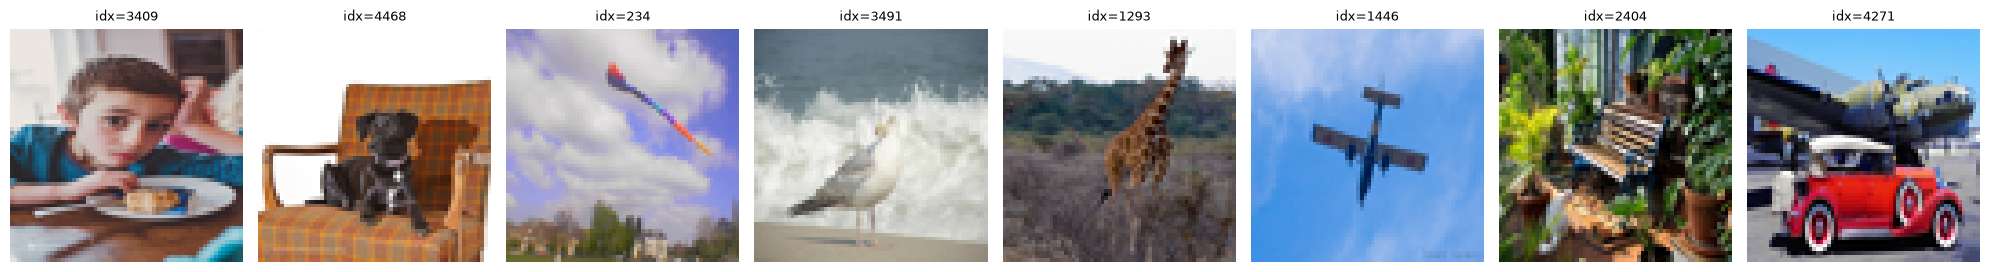

In [90]:
indices = [1596, 3128, 596, 1781, 1771] # Main
indices = [3409, 4468, 234, 3491, 1293, 1446, 2404, 4271]


num_images = len(indices)

fig, axes = plt.subplots(1, num_images, figsize=(2.5 * num_images, 2.8))

if num_images == 1:
    axes = [axes]

for ax, idx in zip(axes, indices):
    image, _ = val_dataset[idx]
    image = denormalize_image(image)
    image = image.permute(1, 2, 0).cpu().numpy()

    # All annotated categories in this COCO image.
    category_names = [val_dataset.idx_to_label[cid] for cid in val_dataset.category_ids[idx]]

    ax.imshow(image)
    ax.set_title(f"idx={idx}", fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [107]:
category_indices = {
    # "person": 4511,
    # "person": 1290,
    "person": 1008,
    # "airplane": 1596,
    "dog": 3128,
    "clock": 596,
    "surfboard": 1781,
    "bicycle": 1771,
}

category_indices = {
    "person": 3409,
    # "person": 4511,
    "chair": 4468,
    "kite": 234,
    "bird": 3491,
    "giraffe": 1293,
    "car": 4271,
    "bench": 2404,
    "airplane": 1446,
}

visual_indices = {}

for category, idx in category_indices.items():
    category_id = val_dataset.class_to_idx[category]

    # Sanity check: selected image really contains the requested category.
    assert category_id in val_dataset.category_ids[idx], (
        f"Image index {idx} does not contain category "
        f"'{category}' (COCO category id {category_id})."
    )

    visual_indices[category_id] = idx

    all_categories = [
        val_dataset.idx_to_label[cid]
        for cid in val_dataset.category_ids[idx]
    ]

    print(
        f"{category_id:2d}: {category:10s} "
        f"idx={idx:4d} "
        f"all categories={all_categories}"
    )


experiment_dir = Path(
    "/tmp/data/experiments/qualitative/coco-2017/seed-42/"
)

baseline_order = [
    "original",
    "vq_coco_16x16_k1024_d64",
    "vqema_coco_16x16_k1024_d64",
    "fsq_coco_16x16_k1000_d64",
    "avq_coco_16x16_k1024_d64",
    "rvqema_coco_16x16_q3_k1024_d64",
    "arvq_coco_16x16_q3_k1024_d64",
]

baseline_row_names = [
    "Original",
    "VQ",
    "VQ-EMA",
    "FSQ",
    "AVQ",
    "RVQ-EMA",
    "ARVQ",
]

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

 1: person     idx=3409 all categories=['person', 'knife', 'cake', 'dining table']
62: chair      idx=4468 all categories=['dog', 'chair']
38: kite       idx= 234 all categories=['person', 'kite']
16: bird       idx=3491 all categories=['bird']
25: giraffe    idx=1293 all categories=['giraffe']
 3: car        idx=4271 all categories=['person', 'car', 'airplane']
15: bench      idx=2404 all categories=['bench', 'cat', 'potted plant']
 5: airplane   idx=1446 all categories=['airplane']


In [108]:
def plot_reconstruction_grid(
    experiment_order,
    row_names,
    visual_indices,
    experiment_dir,
    val_dataset,
    idx_to_label,
    figsize=None,
    save_path=None,
):
    device = torch.device(
        "cuda" if torch.cuda.is_available()
        else "cpu"
    )

    nrows = len(experiment_order)
    ncols = len(visual_indices)

    if figsize is None:
        figsize = (12, 1.8 * nrows)

    fig, axes = plt.subplots(
        nrows,
        ncols,
        figsize=figsize,
        squeeze=False,
    )

    # Each item is:
    #   (COCO category id, validation dataset index)
    visual_items = list(
        visual_indices.items()
    )

    # --------------------------------------------------------
    # Column titles
    # --------------------------------------------------------
    #
    # IMPORTANT:
    # COCOImageDataset returns dummy target=0.
    # Therefore use category_id from visual_indices,
    # NOT the returned dataset target.
    #
    for col, (category_id, idx) in enumerate(
        visual_items
    ):

        class_name = idx_to_label[
            category_id
        ]

        axes[0, col].set_title(
            class_name.title(),
            fontsize=8,
            fontweight="bold",
        )

    # --------------------------------------------------------
    # Rows
    # --------------------------------------------------------

    for row, experiment_name in enumerate(
        experiment_order
    ):

        if experiment_name == "original":

            for col, (_, idx) in enumerate(
                visual_items
            ):

                # Returned label is dummy and ignored.
                image, _ = val_dataset[idx]

                display_image = (
                    denormalize_image(image)
                    .permute(1, 2, 0)
                    .cpu()
                    .numpy()
                )

                axes[row, col].imshow(
                    display_image
                )

        else:

            method = experiment_name.split(
                "_"
            )[0]

            checkpoint = get_checkpoint_path(
                experiment_name,
                experiment_dir,
            )

            if not checkpoint.exists():
                raise FileNotFoundError(
                    f"Checkpoint not found:\n"
                    f"{checkpoint}"
                )

            print(
                f"Loading {experiment_name}:\n"
                f"  {checkpoint}"
            )

            model = load_model(
                experiment_name,
                checkpoint,
                device,
            )

            for col, (_, idx) in enumerate(
                visual_items
            ):

                image, _ = val_dataset[idx]

                reconstruction = (
                    reconstruct_image(
                        method,
                        model,
                        image,
                        device,
                        temperature=0.02,
                    )
                )

                display_image = (
                    denormalize_image(
                        reconstruction
                    )
                    .permute(1, 2, 0)
                    .numpy()
                )

                axes[row, col].imshow(
                    display_image
                )

            del model

            if device.type == "cuda":
                torch.cuda.empty_cache()

        # ----------------------------------------------------
        # Clean axes
        # ----------------------------------------------------

        for col in range(ncols):

            ax = axes[row, col]

            ax.set_xticks([])
            ax.set_yticks([])

            for spine in ax.spines.values():
                spine.set_visible(False)

        # ----------------------------------------------------
        # Method name
        # ----------------------------------------------------

        axes[row, 0].set_ylabel(
            row_names[row],
            fontsize=10,
            fontweight="bold",
            rotation=0,
            labelpad=35,
            va="center",
        )

    plt.subplots_adjust(
        left=0.14,
        right=0.995,
        top=0.95,
        bottom=0.015,
        wspace=0.03,
        hspace=0.08,
    )

    if save_path is not None:
        plt.savefig(
            save_path,
            dpi=300,
            bbox_inches="tight",
            pad_inches=0.02,
        )

    plt.show()

Loading vq_coco_16x16_k1024_d64:
  /tmp/data/experiments/qualitative/coco-2017/seed-42/vq_coco_16x16_k1024_d64/calibration/best_decoder_calibration.pt
Loading vqema_coco_16x16_k1024_d64:
  /tmp/data/experiments/qualitative/coco-2017/seed-42/vqema_coco_16x16_k1024_d64/calibration/best_decoder_calibration.pt
Loading fsq_coco_16x16_k1000_d64:
  /tmp/data/experiments/qualitative/coco-2017/seed-42/fsq_coco_16x16_k1000_d64/calibration/best_decoder_calibration.pt
Loading avq_coco_16x16_k1024_d64:
  /tmp/data/experiments/qualitative/coco-2017/seed-42/avq_coco_16x16_k1024_d64/calibration/best_decoder_calibration.pt
Loading rvqema_coco_16x16_q3_k1024_d64:
  /tmp/data/experiments/qualitative/coco-2017/seed-42/rvqema_coco_16x16_q3_k1024_d64/calibration/best_decoder_calibration.pt
Loading arvq_coco_16x16_q3_k1024_d64:
  /tmp/data/experiments/qualitative/coco-2017/seed-42/arvq_coco_16x16_q3_k1024_d64/calibration/best_arvq_decoder_calibration.pt


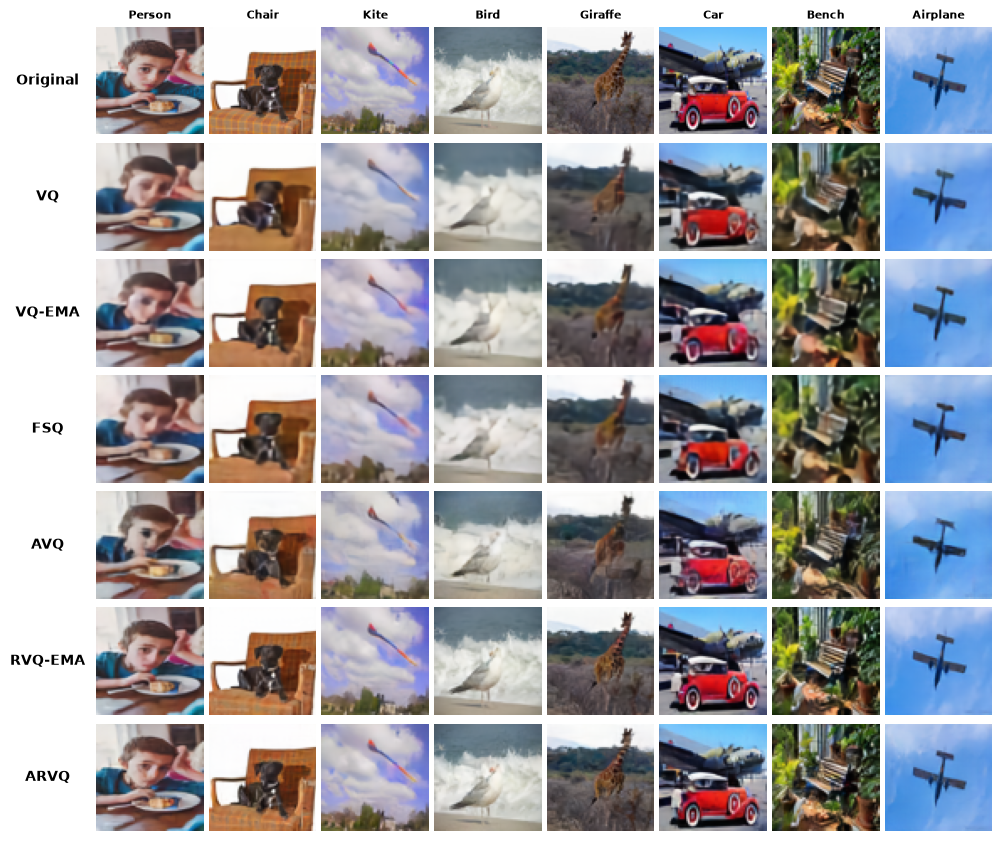

In [109]:
plot_reconstruction_grid(
    experiment_order=baseline_order,
    row_names=baseline_row_names,
    visual_indices=visual_indices,
    experiment_dir=experiment_dir,
    val_dataset=val_dataset,
    idx_to_label=idx_to_label,
    # figsize=(7.2, 9),
    # save_path="coco_reconstructions.pdf",
    figsize=(10.5, 8.6),
    save_path="coco_appendix_reconstructions.pdf",
)

# MiniPlaces

In [36]:
MINIPLACES_ROOT = "/tmp/data/miniplaces"
_, _, val_loader, class_to_idx, idx_to_label = build_mini_places_loaders(
    root_directory=MINIPLACES_ROOT,
    batch_size=64,
    num_workers=4,
    image_size=128,
    seed=15,
    drop_last_train=True,
)

MiniPlaces data loaded
Root: /tmp/data/miniplaces
Number of classes: 100
Training images: 95,000
Training-evaluation images: 5,000
Validation images: 10,000
Training batches: 1,484
Validation batches: 157


In [37]:
val_dataset = val_loader.dataset

print("Validation images:", len(val_dataset))
print("Number of MiniPlaces categories:", len(class_to_idx))

Validation images: 10000
Number of MiniPlaces categories: 100


In [38]:
experiment_dir = Path(
    "/tmp/data/experiments/qualitative/mini-places/seed-42/"
)

baseline_order = [
    "original",
    "vq_32x32_k1024_d64",
    "vqema_32x32_k1024_d64",
    "fsq_32x32_k1000_d64",
    "avq_32x32_k1024_d64",
    "rvqema_32x32_q3_k1024_d64",
    "arvq_32x32_q3_k1024_d64",
]

baseline_row_names = [
    "Original",
    "VQ",
    "VQ-EMA",
    "FSQ",
    "AVQ",
    "RVQ-EMA",
    "ARVQ",
]

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [39]:
# Inspect available COCO categories
for category_name, category_id in sorted(class_to_idx.items(), key=lambda x: x[1]):
    print(f"{category_id:2d}: {category_name:20s}")

 0: abbey               
 1: airport_terminal    
 2: amphitheater        
 3: amusement_park      
 4: aquarium            
 5: aqueduct            
 6: art_gallery         
 7: assembly_line       
 8: auditorium          
 9: badlands            
10: bakery_shop         
11: ballroom            
12: bamboo_forest       
13: banquet_hall        
14: bar                 
15: baseball_field      
16: bathroom            
17: beauty_salon        
18: bedroom             
19: boat_deck           
20: bookstore           
21: botanical_garden    
22: bowling_alley       
23: boxing_ring         
24: bridge              
25: bus_interior        
26: butchers_shop       
27: campsite            
28: candy_store         
29: canyon              
30: cemetery            
31: chalet              
32: church_outdoor      
33: classroom           
34: clothing_store      
35: coast               
36: cockpit             
37: coffee_shop         
38: conference_room     
39: construction_site   


In [40]:
display_names = {
    "airport_terminal": "Airport\nTerminal",
    "bamboo_forest": "Bamboo\nForest",
    "bridge": "Bridge",
    "kitchen": "Kitchen",
    "mountain": "Mountain",
    "supermarket": "Supermarket",
    "swimming_pool_outdoor": "Swimming\nPool",
    "subway_station_platform": "Subway\nPlatform",
}

Selected qualitative images:
airport_terminal          class= 1 idx= 7388
bamboo_forest             class=12 idx= 3373
bridge                    class=24 idx= 9190
kitchen                   class=59 idx= 4187
mountain                  class=68 idx= 9367
supermarket               class=91 idx= 9315
swimming_pool_outdoor     class=93 idx= 8324
subway_station_platform   class=90 idx= 6906


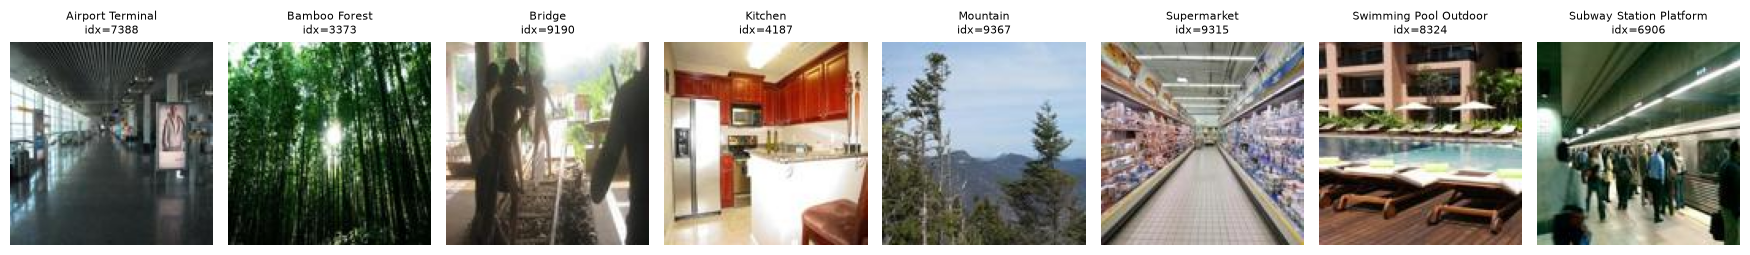

In [64]:
VIS_SEED = 5


rng = random.Random(VIS_SEED)

selected_category_names = [
    "airport_terminal",
    "bamboo_forest",
    "bridge",
    "kitchen",
    "mountain",
    "supermarket",
    "swimming_pool_outdoor",
    "subway_station_platform",
]


# ============================================================
# Build mapping:
# class_id -> list of validation dataset indices
# ============================================================

indices_by_label = defaultdict(list)

for idx in range(len(val_dataset)):
    _, label = val_dataset[idx]

    label = int(label)
    indices_by_label[label].append(idx)


# ============================================================
# Select one deterministic random image from each class
# ============================================================

visual_indices = {}

for category_name in selected_category_names:

    category_id = class_to_idx[category_name]

    eligible_indices = indices_by_label[category_id]

    if len(eligible_indices) == 0:
        raise RuntimeError(
            f"No validation images found for "
            f"'{category_name}' "
            f"(class id {category_id})."
        )

    selected_idx = rng.choice(
        eligible_indices
    )

    visual_indices[category_name] = selected_idx


# ============================================================
# Print selections
# ============================================================

print("Selected qualitative images:")

for category_name, idx in visual_indices.items():

    _, actual_label = val_dataset[idx]

    print(
        f"{category_name:25s} "
        f"class={int(actual_label):2d} "
        f"idx={idx:5d}"
    )


# ============================================================
# Preview
# ============================================================

def denormalize_image(x):
    # [-1, 1] -> [0, 1]
    return ((x + 1.0) / 2.0).clamp(0, 1)


num_images = len(visual_indices)

fig, axes = plt.subplots(
    1,
    num_images,
    figsize=(2.2 * num_images, 2.6),
)

if num_images == 1:
    axes = [axes]


for ax, (selected_category, idx) in zip(
    axes,
    visual_indices.items(),
):

    image, actual_label = val_dataset[idx]

    image = denormalize_image(image)

    image = (
        image
        .permute(1, 2, 0)
        .cpu()
        .numpy()
    )

    actual_label = int(actual_label)

    ax.imshow(image)

    ax.set_title(
        f"{selected_category.replace('_', ' ').title()}\n"
        f"idx={idx}",
        fontsize=8,
    )

    ax.axis("off")


plt.tight_layout()
plt.show()

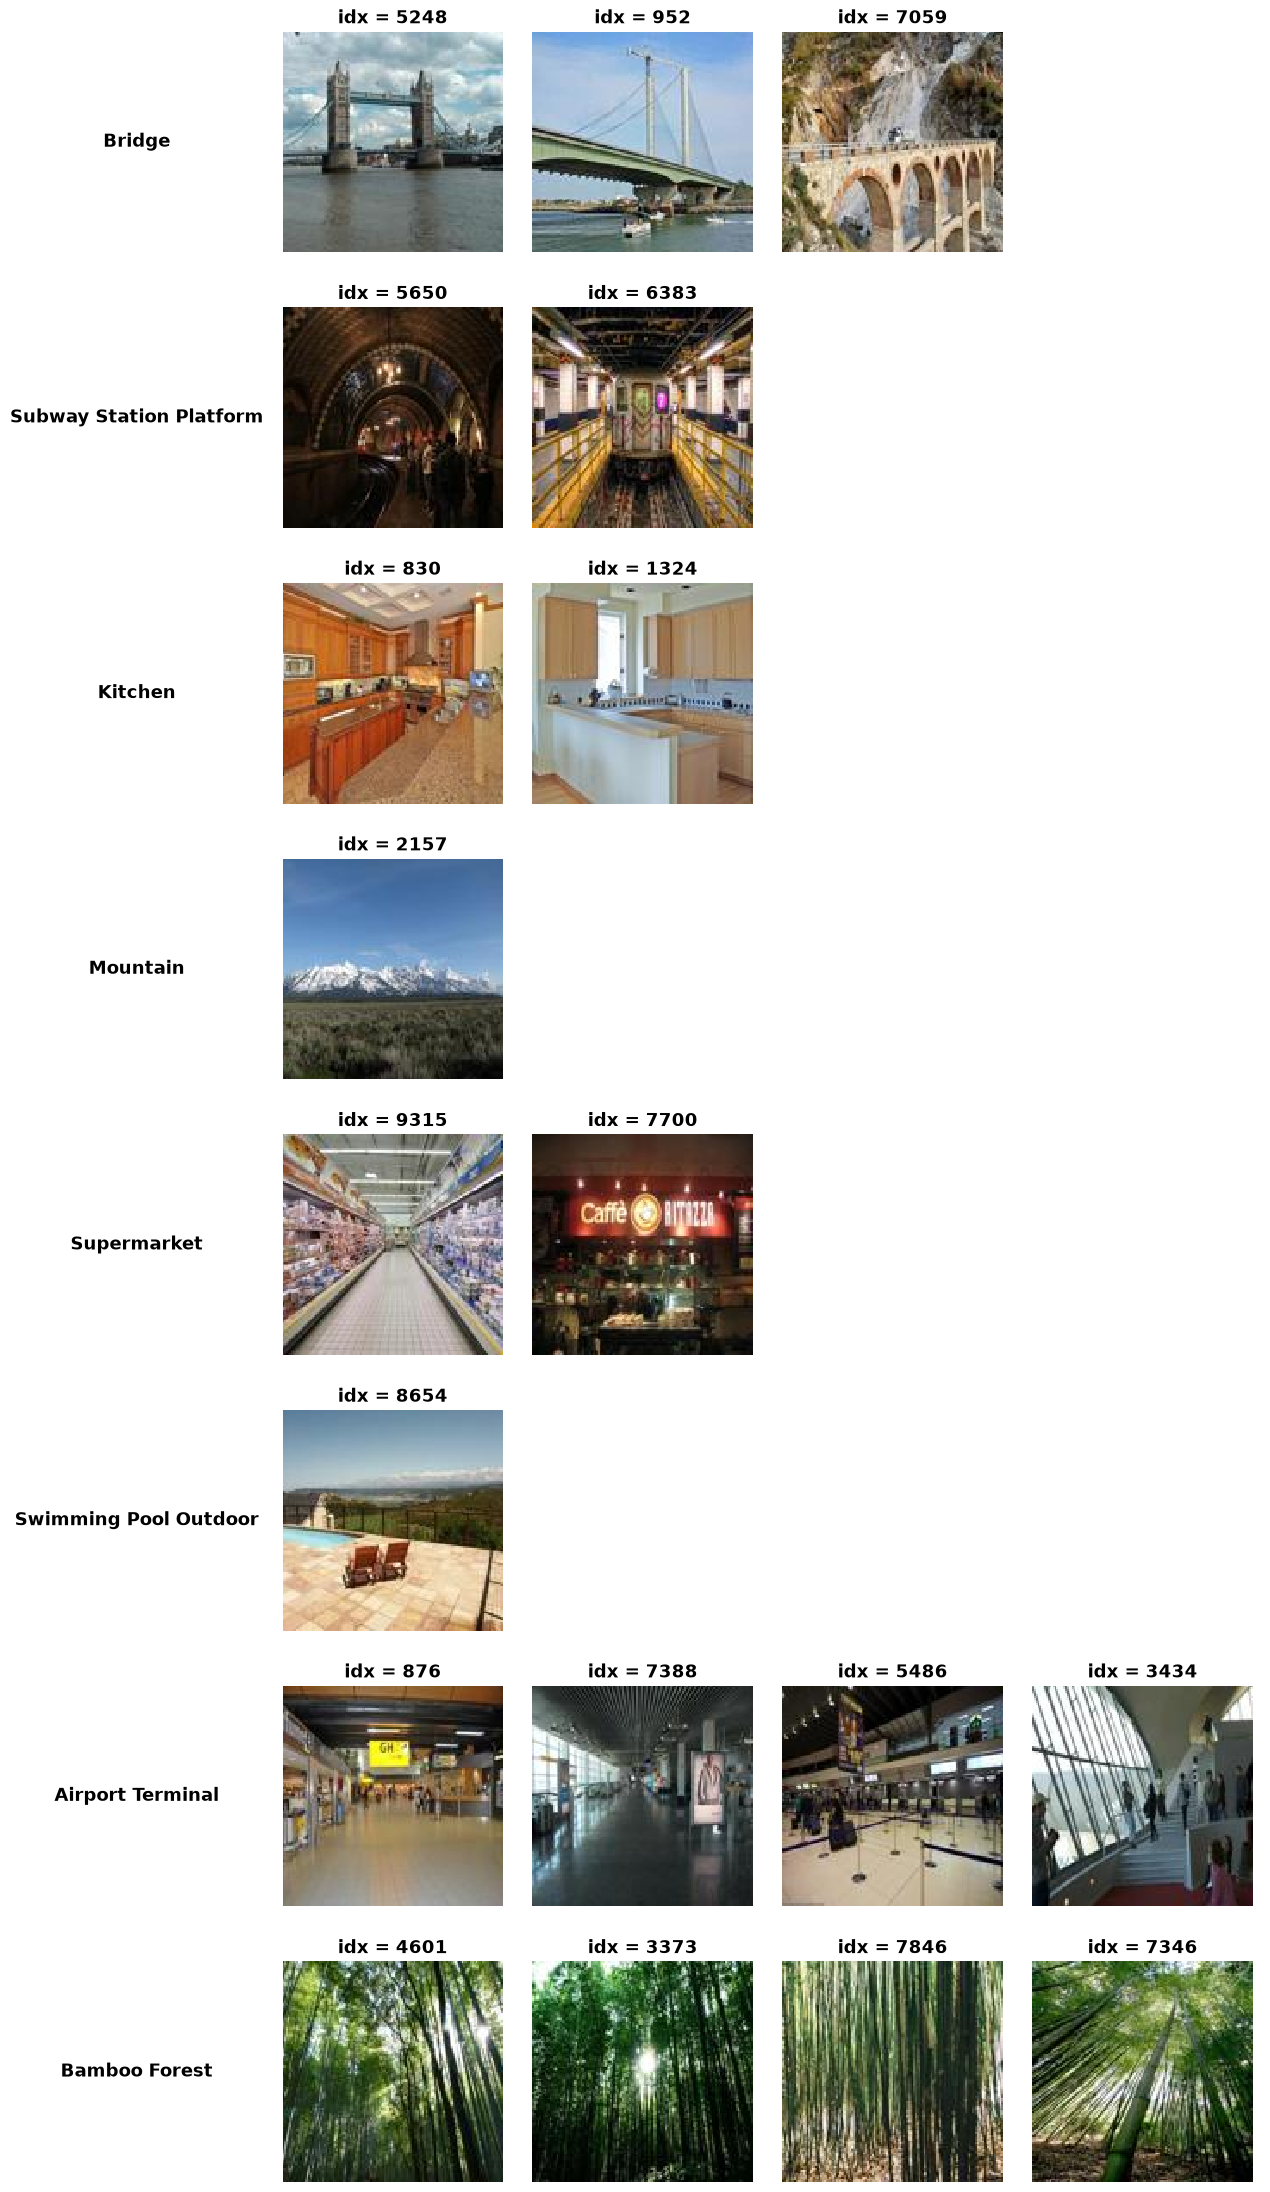

In [62]:


# ============================================================
# Candidate MiniPlaces images
# ============================================================

candidate_indices = {
    "bridge": [5248, 952, 7059],
    "subway_station_platform": [5650, 6383],
    "kitchen": [830, 1324],
    "mountain": [2157],
    "supermarket": [9315, 7700],
    "swimming_pool_outdoor": [8654],
    "airport_terminal": [876, 7388, 5486, 3434],
    "bamboo_forest": [4601, 3373, 7846, 7346],
}


def denormalize_image(image):
    """Convert image from [-1, 1] to [0, 1]."""
    return ((image + 1.0) / 2.0).clamp(0, 1)


# ============================================================
# Plot candidate images
# ============================================================

nrows = len(candidate_indices)
ncols = max(len(indices) for indices in candidate_indices.values())

# Larger images for visual inspection.
fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(3.2 * ncols, 2.8 * nrows),
    squeeze=False,
)


for row, (category_name, indices) in enumerate(candidate_indices.items()):

    expected_label = class_to_idx[category_name]

    for col in range(ncols):

        ax = axes[row, col]

        # Empty location when a category has fewer candidates.
        if col >= len(indices):
            ax.axis("off")
            continue

        idx = indices[col]

        image, actual_label = val_dataset[idx]
        actual_label = int(actual_label)

        # ----------------------------------------------------
        # Sanity check
        # ----------------------------------------------------

        if actual_label != expected_label:
            print(
                f"WARNING: idx={idx}: "
                f"expected '{category_name}' "
                f"(label={expected_label}), "
                f"but dataset returned label={actual_label}"
            )

        # ----------------------------------------------------
        # Prepare image for display
        # ----------------------------------------------------

        display_image = (
            denormalize_image(image)
            .permute(1, 2, 0)
            .cpu()
            .numpy()
        )

        ax.imshow(
            display_image,
            interpolation="nearest",
        )

        ax.set_title(
            f"idx = {idx}",
            fontsize=13,
            fontweight="bold",
            pad=6,
        )

        ax.set_xticks([])
        ax.set_yticks([])

        for spine in ax.spines.values():
            spine.set_visible(False)

    # --------------------------------------------------------
    # Category name on left
    # --------------------------------------------------------

    display_category = (
        category_name
        .replace("_", " ")
        .title()
    )

    axes[row, 0].set_ylabel(
        display_category,
        fontsize=13,
        fontweight="bold",
        rotation=0,
        labelpad=105,
        va="center",
        ha="center",
    )


# ============================================================
# Spacing
# ============================================================

plt.subplots_adjust(
    left=0.22,
    right=0.99,
    top=0.98,
    bottom=0.02,
    wspace=0.06,
    hspace=0.25,
)


# ============================================================
# Optional save
# ============================================================

plt.savefig(
    "miniplaces_candidate_images.pdf",
    bbox_inches="tight",
    pad_inches=0.03,
)

plt.savefig(
    "miniplaces_candidate_images.png",
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.03,
)

plt.show()

In [69]:
import textwrap


def plot_reconstruction_grid_miniplaces(
    experiment_order,
    row_names,
    visual_indices,
    experiment_dir,
    val_dataset,
    figsize=None,
    save_path=None,
):
    """
    Plot MiniPlaces qualitative reconstructions.

    visual_indices:
        dict mapping category name -> validation dataset index

        Example:
        {
            "bridge": 7059,
            "subway_station_platform": 5650,
            "kitchen": 830,
            ...
        }
    """

    device = torch.device(
        "cuda" if torch.cuda.is_available()
        else "cpu"
    )

    nrows = len(experiment_order)
    ncols = len(visual_indices)

    if figsize is None:
        # Good size for 8 columns x 7 rows.
        figsize = (13.5, 9.0)

    fig, axes = plt.subplots(
        nrows,
        ncols,
        figsize=figsize,
        squeeze=False,
    )

    # Each item is:
    #   (MiniPlaces category name, validation dataset index)
    visual_items = list(visual_indices.items())

    # ========================================================
    # Column titles
    # ========================================================

    for col, (category_name, idx) in enumerate(visual_items):

        # Convert:
        # subway_station_platform -> Subway Station Platform
        class_name = (
            category_name
            .replace("_", " ")
            .title()
        )

        # Wrap long class names onto two lines.
        class_name = "\n".join(
            textwrap.wrap(
                class_name,
                width=13,
            )
        )

        axes[0, col].set_title(
            class_name,
            fontsize=8,
            fontweight="bold",
            pad=5,
            linespacing=0.9,
        )

    # ========================================================
    # Rows
    # ========================================================

    for row, experiment_name in enumerate(
        experiment_order
    ):

        # ----------------------------------------------------
        # Original images
        # ----------------------------------------------------

        if experiment_name == "original":

            for col, (_, idx) in enumerate(
                visual_items
            ):

                image, _ = val_dataset[idx]

                display_image = (
                    denormalize_image(image)
                    .permute(1, 2, 0)
                    .cpu()
                    .numpy()
                )

                axes[row, col].imshow(
                    display_image,
                    interpolation="nearest",
                )

        # ----------------------------------------------------
        # Reconstructions
        # ----------------------------------------------------

        else:

            method = experiment_name.split("_")[0]

            checkpoint = get_checkpoint_path(
                experiment_name,
                experiment_dir,
            )

            if not checkpoint.exists():
                raise FileNotFoundError(
                    f"Checkpoint not found:\n"
                    f"{checkpoint}"
                )

            print(
                f"Loading {experiment_name}:\n"
                f"  {checkpoint}"
            )

            model = load_model(
                experiment_name,
                checkpoint,
                device,
            )

            for col, (_, idx) in enumerate(
                visual_items
            ):

                image, _ = val_dataset[idx]

                reconstruction = reconstruct_image(
                    method,
                    model,
                    image,
                    device,
                    temperature=0.02,
                )

                display_image = (
                    denormalize_image(
                        reconstruction
                    )
                    .permute(1, 2, 0)
                    .numpy()
                )

                axes[row, col].imshow(
                    display_image,
                    interpolation="nearest",
                )

            del model

            if device.type == "cuda":
                torch.cuda.empty_cache()

        # ====================================================
        # Clean axes
        # ====================================================

        for col in range(ncols):

            ax = axes[row, col]

            ax.set_xticks([])
            ax.set_yticks([])

            for spine in ax.spines.values():
                spine.set_visible(False)

        # ====================================================
        # Method name on left
        # ====================================================

        # axes[row, 0].set_ylabel(
        #     row_names[row],
        #     fontsize=9,
        #     fontweight="bold",
        #     rotation=0,
        #     labelpad=29,
        #     va="center",
        # )

        axes[row, 0].set_ylabel(
            row_names[row],
            fontsize=9,
            fontweight="bold",
            rotation=0,
            labelpad=22,
            va="center",
        )

    # ========================================================
    # Figure spacing
    # ========================================================

    plt.subplots_adjust(
        left=0.085,
        right=0.995,
        top=0.945,
        bottom=0.01,
        wspace=0.01,
        hspace=0.035,
    )

    # ========================================================
    # Save
    # ========================================================

    if save_path is not None:

        plt.savefig(
            save_path,
            dpi=300,
            bbox_inches="tight",
            pad_inches=0.02,
        )

        print(
            f"Saved figure to: {save_path}"
        )

    plt.show()

In [70]:
experiment_dir = Path(
    "/tmp/data/experiments/qualitative/mini-places/seed-42/"
)

baseline_order = [
    "original",
    "vq_32x32_k1024_d64",
    "vqema_32x32_k1024_d64",
    "fsq_32x32_k1000_d64",
    "avq_32x32_k1024_d64",
    "rvqema_32x32_q3_k1024_d64",
    "arvq_32x32_q3_k1024_d64",
]

baseline_row_names = [
    "Original",
    "VQ",
    "VQ-EMA",
    "FSQ",
    "AVQ",
    "RVQ-EMA",
    "ARVQ",
]

In [71]:
visual_indices = {
    "bridge": 7059,
    "subway_station_platform": 5650,   # replace if needed
    "kitchen": 830,                    # replace if needed
    "mountain": 2157,
    "supermarket": 9315,               # replace if needed
    "swimming_pool_outdoor": 8654,
    "airport_terminal": 876,           # replace if needed
    "bamboo_forest": 4601,             # replace if needed
}

Loading vq_32x32_k1024_d64:
  /tmp/data/experiments/qualitative/mini-places/seed-42/vq_32x32_k1024_d64/calibration/best_decoder_calibration.pt
Loading vqema_32x32_k1024_d64:
  /tmp/data/experiments/qualitative/mini-places/seed-42/vqema_32x32_k1024_d64/calibration/best_decoder_calibration.pt
Loading fsq_32x32_k1000_d64:
  /tmp/data/experiments/qualitative/mini-places/seed-42/fsq_32x32_k1000_d64/calibration/best_decoder_calibration.pt
Loading avq_32x32_k1024_d64:
  /tmp/data/experiments/qualitative/mini-places/seed-42/avq_32x32_k1024_d64/calibration/best_decoder_calibration.pt
Loading rvqema_32x32_q3_k1024_d64:
  /tmp/data/experiments/qualitative/mini-places/seed-42/rvqema_32x32_q3_k1024_d64/calibration/best_decoder_calibration.pt
Loading arvq_32x32_q3_k1024_d64:
  /tmp/data/experiments/qualitative/mini-places/seed-42/arvq_32x32_q3_k1024_d64/calibration/best_arvq_decoder_calibration.pt
Saved figure to: miniplaces_reconstructions.pdf


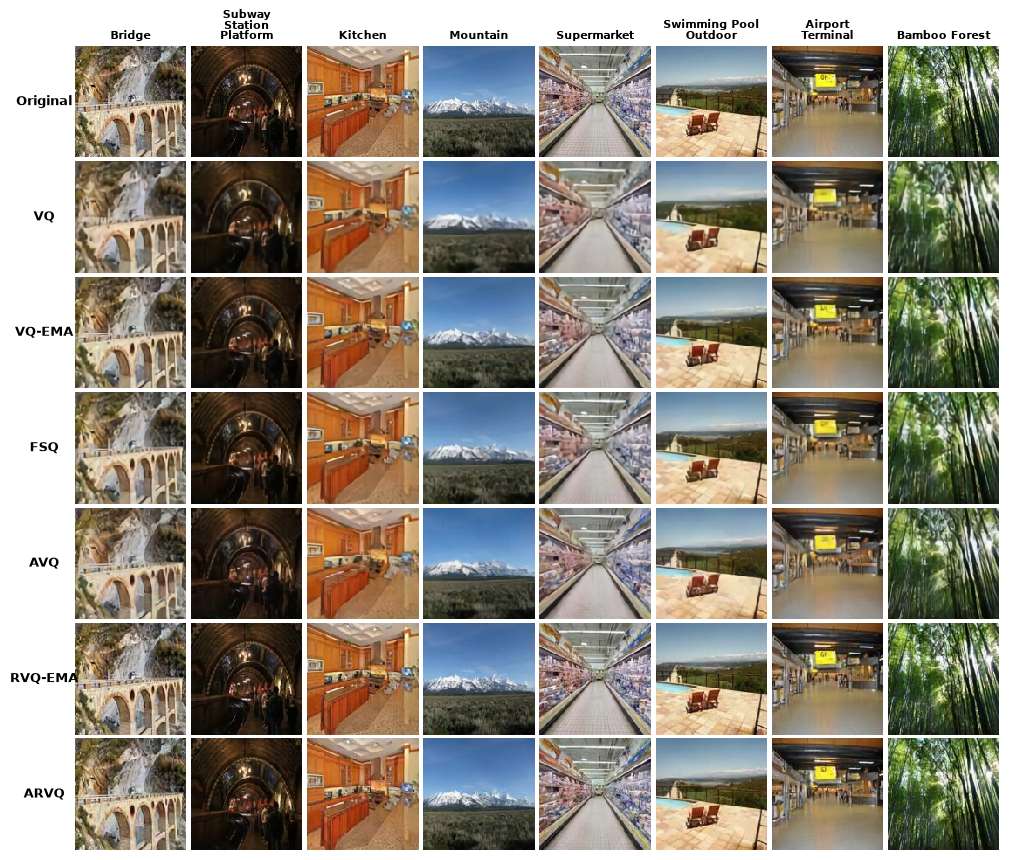

In [77]:
plot_reconstruction_grid_miniplaces(
    experiment_order=baseline_order,
    row_names=baseline_row_names,
    visual_indices=visual_indices,
    experiment_dir=experiment_dir,
    val_dataset=val_dataset,
    figsize=(10.2, 8.6),
    save_path="miniplaces_reconstructions.pdf",
)

In [85]:


def plot_reconstruction_grid_miniplaces(
    experiment_order,
    row_names,
    visual_indices,
    experiment_dir,
    val_dataset,
    figsize=(9.6, 8.6),
    save_path=None,
):
    """
    Plot MiniPlaces qualitative reconstructions.

    visual_indices:
        dict mapping category name -> validation dataset index

    Example:
        {
            "bridge": 7059,
            "subway_station_platform": 5650,
            "kitchen": 830,
            "mountain": 2157,
            "supermarket": 9315,
            "swimming_pool_outdoor": 8654,
            "airport_terminal": 876,
            "bamboo_forest": 4601,
        }
    """

    device = torch.device(
        "cuda" if torch.cuda.is_available()
        else "cpu"
    )

    nrows = len(experiment_order)
    ncols = len(visual_indices)

    fig, axes = plt.subplots(
        nrows,
        ncols,
        figsize=figsize,
        squeeze=False,
    )

    visual_items = list(visual_indices.items())

    # --------------------------------------------------------
    # Shorter, paper-friendly column titles
    # --------------------------------------------------------

    display_title_names = {
        "bridge": "Bridge",
        "subway_station_platform": "Subway Platform",
        "kitchen": "Kitchen",
        "mountain": "Mountain",
        "supermarket": "Supermarket",
        "swimming_pool_outdoor": "Outdoor Pool",
        "airport_terminal": "Airport Terminal",
        "bamboo_forest": "Bamboo Forest",
    }

    # --------------------------------------------------------
    # Column titles
    # --------------------------------------------------------

    for col, (category_name, idx) in enumerate(
        visual_items
    ):
        class_name = display_title_names.get(
            category_name,
            category_name.replace("_", " ").title(),
        )

        axes[0, col].set_title(
            class_name,
            fontsize=8,
            fontweight="bold",
            pad=4,
        )

    # --------------------------------------------------------
    # Rows
    # --------------------------------------------------------

    for row, experiment_name in enumerate(
        experiment_order
    ):

        # ====================================================
        # Original images
        # ====================================================

        if experiment_name == "original":

            for col, (_, idx) in enumerate(
                visual_items
            ):
                image, _ = val_dataset[idx]

                display_image = (
                    denormalize_image(image)
                    .permute(1, 2, 0)
                    .cpu()
                    .numpy()
                )

                axes[row, col].imshow(
                    display_image,
                    interpolation="nearest",
                )

        # ====================================================
        # Reconstructions
        # ====================================================

        else:

            method = experiment_name.split("_")[0]

            checkpoint = get_checkpoint_path(
                experiment_name,
                experiment_dir,
            )

            if not checkpoint.exists():
                raise FileNotFoundError(
                    f"Checkpoint not found:\n"
                    f"{checkpoint}"
                )

            print(
                f"Loading {experiment_name}:\n"
                f"  {checkpoint}"
            )

            model = load_model(
                experiment_name,
                checkpoint,
                device,
            )

            for col, (_, idx) in enumerate(
                visual_items
            ):

                image, _ = val_dataset[idx]

                reconstruction = reconstruct_image(
                    method,
                    model,
                    image,
                    device,
                    temperature=0.02,
                )

                display_image = (
                    denormalize_image(
                        reconstruction
                    )
                    .permute(1, 2, 0)
                    .numpy()
                )

                axes[row, col].imshow(
                    display_image,
                    interpolation="nearest",
                )

            del model

            if device.type == "cuda":
                torch.cuda.empty_cache()

        # ====================================================
        # Clean axes
        # ====================================================

        for col in range(ncols):

            ax = axes[row, col]

            ax.set_xticks([])
            ax.set_yticks([])

            for spine in ax.spines.values():
                spine.set_visible(False)

        # ====================================================
        # Method name on left
        # ====================================================

        axes[row, 0].set_ylabel(
            row_names[row],
            fontsize=9,
            fontweight="bold",
            rotation=0,
            labelpad=28,
            va="center",
        )

    # --------------------------------------------------------
    # Tight spacing
    # --------------------------------------------------------

    plt.subplots_adjust(
        left=0.085,
        right=0.995,
        top=0.945,
        bottom=0.01,
        wspace=0.01,
        hspace=0.035,
    )

    # --------------------------------------------------------
    # Save
    # --------------------------------------------------------

    if save_path is not None:
        plt.savefig(
            save_path,
            dpi=300,
            bbox_inches="tight",
            pad_inches=0.02,
        )

        print(
            f"Saved figure to: {save_path}"
        )

    plt.show()

Loading vq_32x32_k1024_d64:
  /tmp/data/experiments/qualitative/mini-places/seed-42/vq_32x32_k1024_d64/calibration/best_decoder_calibration.pt
Loading vqema_32x32_k1024_d64:
  /tmp/data/experiments/qualitative/mini-places/seed-42/vqema_32x32_k1024_d64/calibration/best_decoder_calibration.pt
Loading fsq_32x32_k1000_d64:
  /tmp/data/experiments/qualitative/mini-places/seed-42/fsq_32x32_k1000_d64/calibration/best_decoder_calibration.pt
Loading avq_32x32_k1024_d64:
  /tmp/data/experiments/qualitative/mini-places/seed-42/avq_32x32_k1024_d64/calibration/best_decoder_calibration.pt
Loading rvqema_32x32_q3_k1024_d64:
  /tmp/data/experiments/qualitative/mini-places/seed-42/rvqema_32x32_q3_k1024_d64/calibration/best_decoder_calibration.pt
Loading arvq_32x32_q3_k1024_d64:
  /tmp/data/experiments/qualitative/mini-places/seed-42/arvq_32x32_q3_k1024_d64/calibration/best_arvq_decoder_calibration.pt
Saved figure to: miniplaces_reconstructions.pdf


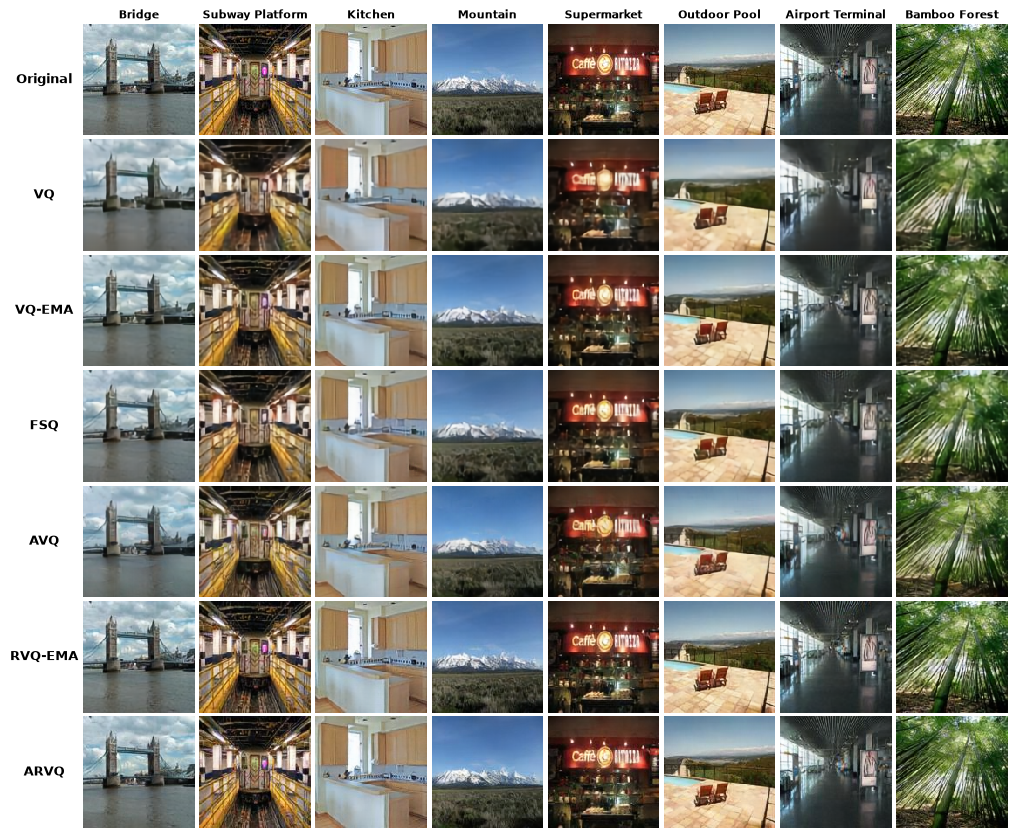

In [86]:
visual_indices = {
    "bridge": 5248,
    "subway_station_platform": 6383,
    "kitchen": 1324,
    "mountain": 2157,
    "supermarket": 7700,
    "swimming_pool_outdoor": 8654,
    "airport_terminal": 7388,
    "bamboo_forest": 7346,
}


experiment_dir = Path(
    "/tmp/data/experiments/qualitative/mini-places/seed-42/"
)


baseline_order = [
    "original",
    "vq_32x32_k1024_d64",
    "vqema_32x32_k1024_d64",
    "fsq_32x32_k1000_d64",
    "avq_32x32_k1024_d64",
    "rvqema_32x32_q3_k1024_d64",
    "arvq_32x32_q3_k1024_d64",
]


baseline_row_names = [
    "Original",
    "VQ",
    "VQ-EMA",
    "FSQ",
    "AVQ",
    "RVQ-EMA",
    "ARVQ",
]


plot_reconstruction_grid_miniplaces(
    experiment_order=baseline_order,
    row_names=baseline_row_names,
    visual_indices=visual_indices,
    experiment_dir=experiment_dir,
    val_dataset=val_dataset,
    figsize=(10.2, 8.6),
    save_path="miniplaces_reconstructions.pdf",
)